# Categorical data

Meaning = finite number of groups (or categories)
These categories are usually fixed or known (eye color, hair color, etc). Known as qualitative data. 

### Ordinal vs nominal

Ordinal - natural order. for example survey answers

Nominal - no natural order. colors for example

In [2]:
import kagglehub
import os
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("uciml/adult-census-income")

print("Path to dataset files:", path)

Path to dataset files: /home/jubel/.cache/kagglehub/datasets/uciml/adult-census-income/versions/3


In [3]:
csv_path = os.path.join(path, 'adult.csv')
adult = pd.read_csv(csv_path)

In [4]:
adult.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [5]:
adult['marital.status'].describe()

count                  32561
unique                     7
top       Married-civ-spouse
freq                   14976
Name: marital.status, dtype: object

In [6]:
adult['marital.status'].value_counts(normalize=True)

#prints frequency table 

marital.status
Married-civ-spouse       0.459937
Never-married            0.328092
Divorced                 0.136452
Separated                0.031479
Widowed                  0.030497
Married-spouse-absent    0.012837
Married-AF-spouse        0.000706
Name: proportion, dtype: float64

In [7]:
adult.dtypes

age               int64
workclass           str
fnlwgt            int64
education           str
education.num     int64
marital.status      str
occupation          str
relationship        str
race                str
sex                 str
capital.gain      int64
capital.loss      int64
hours.per.week    int64
native.country      str
income              str
dtype: object

by default, columns containing strings are not stored using pandas' category dtype, as not every column containing strings needs to be categorical. 

In [8]:
adult['marital.status'].dtype

<StringDtype(storage='python', na_value=nan)>

we can convert this to the categorical dtype using the astype method and specifying category

In [9]:
adult['marital.status'] = adult['marital.status'].astype('category')
adult['marital.status'].dtype

CategoricalDtype(categories=['Divorced', 'Married-AF-spouse', 'Married-civ-spouse',
                  'Married-spouse-absent', 'Never-married', 'Separated',
                  'Widowed'],
, ordered=False, categories_dtype=str)

There are two ways to create a categorical pandas Series when your data is not already in a DataFrame format. 

In [10]:
my_data = ['A', 'A', 'C', 'B', 'B', 'A']
pd.Series(my_data, dtype='category')

0    A
1    A
2    C
3    B
4    B
5    A
dtype: category
Categories (3, str): ['A', 'B', 'C']

In [11]:
pd.Categorical(my_data, categories=['C', 'B', 'A'], ordered=True)

['A', 'A', 'C', 'B', 'B', 'A']
Categories (3, str): ['C' < 'B' < 'A']

This alternative way allows us to tell pandas that the categories have a logical order. It will be the order in categories=

There are a few reasons why storing pandas Series with a dtype of categorical is useful. 

It is a huge memory saver!

Series.nbytes

If you know the data types of columns before reading in a data set, it is good practice to specify at least some of the column dtypes. This can be done by creating a dict with column names as keys and data types as values.

In [12]:
adult_dtypes = {"marital.status" : "category"}

adult = pd.read_csv(csv_path, dtype=adult_dtypes)

## Grouping data by category in pandas

The .groupby() method splits data across the unique values of the column specified. One of the most common forms of data analysis is to split data across groups and to perform analyis on each group. The groupby process is essentially equal to creating multiple DataFrames, one for each value in the specified variable.

In [13]:
adult = pd.read_csv(csv_path)
adult1 = adult[adult['income'] == "<=50K"]
adult2 = adult[adult['income'] == ">=50K"]

The above can be replaces by a single line using groupby

In [14]:
groupby_object = adult.groupby(by=['income'])

You can specify a function that should be applied to the split data.  Sum, count, mean.... or custom functions.

groupby_object.mean()

## Groupby multiple columns

by specifying the two columns with the by parameter, the groupby method will create subsets of the data for all combinations of the variables specified

In [15]:
adult.groupby(by=['income', 'marital.status']).size()

income  marital.status       
<=50K   Divorced                  3980
        Married-AF-spouse           13
        Married-civ-spouse        8284
        Married-spouse-absent      384
        Never-married            10192
        Separated                  959
        Widowed                    908
>50K    Divorced                   463
        Married-AF-spouse           10
        Married-civ-spouse        6692
        Married-spouse-absent       34
        Never-married              491
        Separated                   66
        Widowed                     85
dtype: int64

this created 14 different groupings. When calling groupby on multiple variables, it is important to check the size of each combination to make sure there are enough rows per combination to do analysis.

For example, the combo more than 50K and Married-AF-spuse only has 10 rows of data.

If no rows exist for a combination of the variables, it will not be added to the groupby object.

## Setting category variables

To get the most out of using the pandas categorical dtype, we need to understand how to set, add and remove categories.

In [16]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jmolitoris/adoptable-dogs")

print("Path to dataset files:", path)

csv_path = os.path.join(path, 'ShelterDogs.csv')

dogs = pd.read_csv(csv_path)



Path to dataset files: /home/jubel/.cache/kagglehub/datasets/jmolitoris/adoptable-dogs/versions/1


In [17]:
dogs.info()

<class 'pandas.DataFrame'>
RangeIndex: 2937 entries, 0 to 2936
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 2937 non-null   int64  
 1   name               2845 non-null   str    
 2   age                2937 non-null   float64
 3   sex                2937 non-null   str    
 4   breed              2937 non-null   str    
 5   date_found         2937 non-null   str    
 6   adoptable_from     2937 non-null   str    
 7   posted             2937 non-null   str    
 8   color              2937 non-null   str    
 9   coat               2937 non-null   str    
 10  size               2937 non-null   str    
 11  neutered           1852 non-null   str    
 12  housebroken        460 non-null    str    
 13  likes_people       1999 non-null   str    
 14  likes_children     1219 non-null   str    
 15  get_along_males    1633 non-null   str    
 16  get_along_females  1673 non-null   

In [18]:
dogs['coat'] = dogs['coat'].astype('category')
dogs['coat'].value_counts(dropna=False) #checking for missing values

coat
short         1972
medium         565
wirehaired     220
long           180
Name: count, dtype: int64

## The .cat accessor object

Series.cat.method_name

This object let's us access and manipulate the categories of a categorical Series. Most of the methods use the following parameters:

- new_categories   
- inplace
- ordered


In [19]:
#cat.set_categories is used to set specific categories for a Series

dogs['coat'] = dogs['coat'].cat.set_categories(
    new_categories=['short', 'medium', 'long'], ordered=True
)

# any any values not listed will be dropped 

dogs['coat'].value_counts(dropna=False)

coat
short     1972
medium     565
NaN        220
long       180
Name: count, dtype: int64

### Missing categories

In [20]:
dogs['likes_people'].value_counts(dropna=False)

likes_people
yes    1991
NaN     938
no        8
Name: count, dtype: int64

#### Adding categories

cat.add_categories()

In [21]:
dogs['likes_people'] = dogs['likes_people'].astype('category')
dogs['likes_people'] = dogs['likes_people'].cat.add_categories(
    new_categories=['did not check', 'could not tell']
)

In [22]:
# check categories

dogs['likes_people'].cat.categories

Index(['no', 'yes', 'did not check', 'could not tell'], dtype='str')

although we added categories, this doesn't mean any rows of our data were set to these categories

### Removing categories

cat.remove_catogories  

 takes removals= []

### Updating categories 

cat.rename_categories(new_categories=dict)

In [23]:
dogs['breed'] = dogs['breed'].astype('category')

my_dict = {'Unknown Mix': 'Unknown'}
dogs['breed'] = dogs['breed'].cat.rename_categories(new_categories=my_dict)

renaming categories with a lambda function

In [24]:
dogs['sex'] = dogs['sex'].astype('category')

In [25]:
dogs['sex'] = dogs['sex'].cat.rename_categories(lambda c: c.title()) 

# the classes of the categories are now in title case: Male instead of male

### common replacement issues

- must use new category names

- cannot collapse two categories into one

### collapsing categories setup



In [26]:
dogs['color']  = dogs['color'].astype('category')

update_colors = {
    'black and brown': 'black',
    'black and tan': 'black',
    'black and white': 'black'
}

dogs['main_color'] = dogs['color'].replace(update_colors)


this method however does not preserve the categorical data type

What is it really doing is replacing every key in our dictionary with every value, but the method is matching strings, not categories. 

Anytime you are updating the underlying string of a category, you will need to convert the Series back to a categorical dtype using the astype method and specifying category

In [27]:
dogs['main_color'] = dogs['main_color'].astype('category')

dogs['main_color'].cat.categories

Index(['apricot', 'black', 'black and brown', 'black and tan',
       'black and white', 'brown', 'brown and white', 'dotted', 'golden',
       'gray', 'gray and black', 'gray and white', 'red', 'red and white',
       'sable', 'saddle back', 'spotty', 'striped', 'tricolor', 'white',
       'wild boar', 'yellow', 'yellow-brown'],
      dtype='str')

Didn't work, got some help from chatgpt

In [28]:
dogs['main_color'] = dogs['main_color'].cat.remove_unused_categories()
dogs['main_color'].cat.categories

Index(['apricot', 'black', 'brown', 'brown and white', 'dotted', 'golden',
       'gray', 'gray and black', 'gray and white', 'red', 'red and white',
       'sable', 'saddle back', 'spotty', 'striped', 'tricolor', 'white',
       'wild boar', 'yellow', 'yellow-brown'],
      dtype='str')

## Reordering categories

why?

1. creating a ordinal variable
2. making analysis result easier to understand
3. converting a Series to categorical can save on memory

In [29]:
dogs['coat'].cat.categories

Index(['short', 'medium', 'long'], dtype='str')

In [30]:
dogs['coat'] = dogs['coat'].cat.reorder_categories(
    new_categories= ['short', 'medium', 'long'],
    ordered=True
)

# we can set ordered=False when we don't want the column treated
# as an ordinal categorical variable

In [31]:
dogs['coat'] = dogs['coat'].cat.reorder_categories(
    new_categories= ['short', 'medium', 'long'],
    ordered=False
)

In [32]:
dogs.groupby(by=['coat'])['age'].mean()

coat
short     8.364746
medium    9.027982
long      9.552056
Name: age, dtype: float64

## Cleaning and accessing data

Data is messy, especially when you are wokring with strings or categories

main issues:

1. Inconsistent values: 'Ham', 'ham', ' Ham'  

2. Misspelled values: 'Ham, 'Hma'

3. Wrong dtype: df['our column'].dtype
If we do make corrections, we need to make sure our column stype remains category, and is not changed to an object.

## Identifying issues

cat.categories
value_counts()


In [33]:
dogs['get_along_cats'].value_counts()

get_along_cats
yes    275
no     156
Name: count, dtype: int64

Here we could see classes like noo, NO etc

### Fixing leading and trailing whitespace

.str.strip()

### Fixing capitalization

.str.title()   or .upper() or .lower()

### Fixing misspelled words

We can used the same mapping methods we learning in the renaming categories lesson.

replace_map = {'Noo': 'No'}

dogs['get_along_cats'].replace(replace_map)

### Checking the data type

If we use on of the above methods, the column will be converted to an Object data type. 



## Using the str accessor object for filtering


In [34]:
dogs['breed'].str.contains('Shepard', regex=False)

#regex string matching and not a regular expression


0       False
1       False
2       False
3       False
4       False
        ...  
2932    False
2933    False
2934    False
2935    False
2936    False
Name: breed, Length: 2937, dtype: bool

all dogs that have some sort of Shepard in ther breed name

## Accessing data with loc
One of the great things about using columns that are categories, is that the data access methods of loc and iloc work like normal

In [35]:
# access Series values based on category
dogs.loc[dogs['get_along_cats'] == 'Yes', 'size']

Series([], Name: size, dtype: str)

In [36]:
# Series value counts:
dogs.loc[dogs['get_along_cats'] == 'Yes', 'size'].value_counts(sort=False)

# the value counts method does not automatically use the 
# categorical order when printing results


Series([], Name: count, dtype: int64)

## Visualizing categorical data

In [37]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("crawford/las-vegas-tripadvisor-reviews")

print("Path to dataset files:", path)

Path to dataset files: /home/jubel/.cache/kagglehub/datasets/crawford/las-vegas-tripadvisor-reviews/versions/2


In [38]:
csv_path = os.path.join(path, 'lasvegas_tripadvisor.csv')
reviews = pd.read_csv(csv_path)

In [39]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   User country       504 non-null    str  
 1   Nr. reviews        504 non-null    int64
 2   Nr. hotel reviews  504 non-null    int64
 3   Helpful votes      504 non-null    int64
 4   Score              504 non-null    int64
 5   Period of stay     504 non-null    str  
 6   Traveler type      504 non-null    str  
 7   Pool               504 non-null    str  
 8   Gym                504 non-null    str  
 9   Tennis court       504 non-null    str  
 10  Spa                504 non-null    str  
 11  Casino             504 non-null    str  
 12  Free internet      504 non-null    str  
 13  Hotel name         504 non-null    str  
 14  Hotel stars        504 non-null    int64
 15  Nr. rooms          504 non-null    int64
 16  User continent     504 non-null    str  
 17  Member years       504 non-

## The catplot function

kind=
    strip
    swarm
    box
    violin
    boxen
    point
    bar
    count



In [40]:
reviews['Score'].value_counts()

Score
5    227
4    164
3     72
2     30
1     11
Name: count, dtype: int64

## Box plot

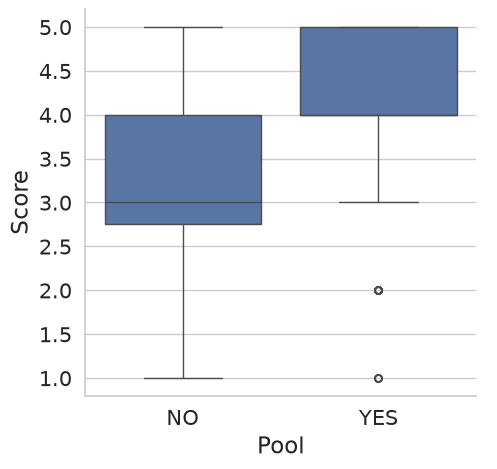

In [41]:
import seaborn as sns

sns.set(font_scale=1.4) # adjusting font size
sns.set_style('whitegrid') # good for reading exact outlier position

sns.catplot(x='Pool', y='Score', kind='box', data=reviews)


## Traditional bar chart 

<Axes: xlabel='Traveler type'>

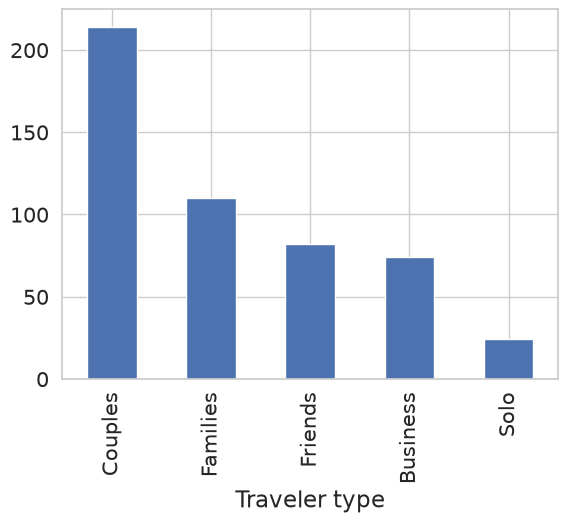

In [42]:
reviews['Traveler type'].value_counts().plot.bar()

This bar chart shows the number of reviews in the data set by the traveler type. This kind of visual creating isn't covered in Seaborn.

## Seaborn bar 

charts serve a different purpose. Our goal is to summarize a numerical variable across the different levels of a categorical variable.

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Business'),
  Text(1, 0, 'Couples'),
  Text(2, 0, 'Families'),
  Text(3, 0, 'Friends'),
  Text(4, 0, 'Solo')])

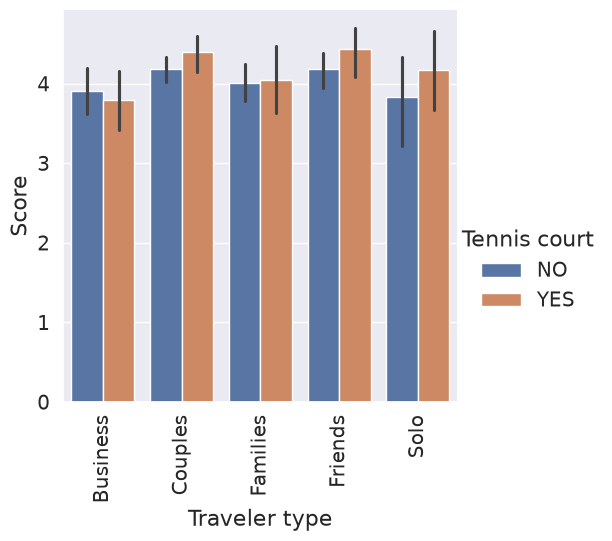

In [43]:
reviews['Traveler type'] = reviews['Traveler type'].astype('category')
reviews['Traveler type'].cat.categories 
# category dtype automatically sets alphabetical order

# it's best practice for us to order our category outside of the catplot-function
import matplotlib.pyplot as plt 


sns.set(font_scale=1.3)
sns.set_style('darkgrid')
sns.catplot(x='Traveler type', y='Score', data=reviews, 
            kind='bar', hue='Tennis court')
plt.xticks(rotation=90)

## Point plot

Shows the mean of the reviewer score just as the bar plot does. However the diagonal line that connects the means help users see the difference between them, and are often more helpful when there are more categories displayed

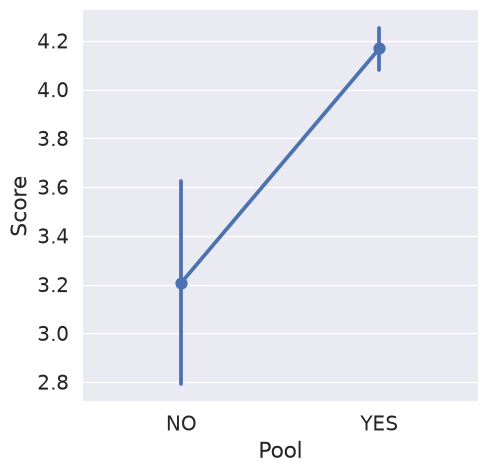

In [44]:
sns.catplot(x='Pool', y='Score', data=reviews, kind='point')

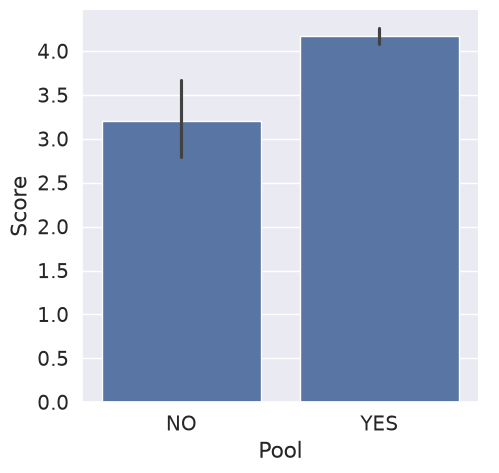

In [45]:
sns.catplot(x='Pool', y='Score', data=reviews, kind='bar')

## Bar plot vs. point plot

When creating visualizations using only one categorical variable, the two visualizations are quite similar. However, the point plot may help users focus on the different values across the categories by adding a connecting line across the points, while the y-axis is changed to better focus on the points.

The bar plot may have a more familiar look and can provide color differences even if only one categorical variable is used. The y.axis for this visual defaults to starting at 0.

## Point plot with hue

the dodge parameter set to True. This offsets the lines so that they don't overlap and makes it easier to see where the mean and intervals fall. 

join=False   removes the connecting lines




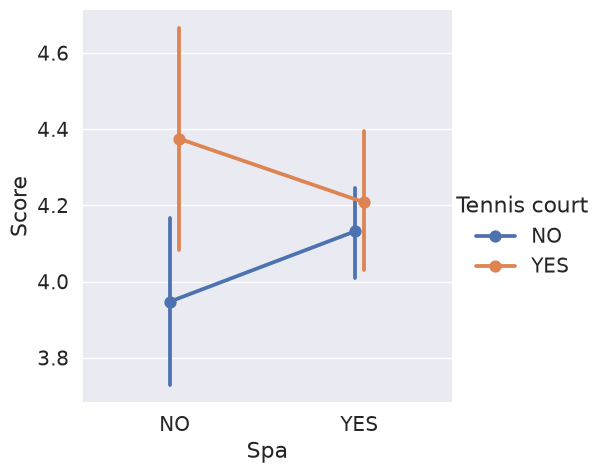

In [46]:
sns.catplot(x='Spa', y='Score', data=reviews, kind='point', 
            hue='Tennis court', dodge=True)

notice that the two colored lines go in different directions. Having a tennis court or not makes a big difference for hotels with no Spa, but hotels with Spas seem to receive similar reviews regardless of if they have a tennis court.

## Count plot

All the other visuals have been aggregating a numerical variable across a categorical variable. This plot simply counts the number of occurences of the categorical variables specified in the x or y and hue parameters.

The catplot count plot is just a typical bar graph....

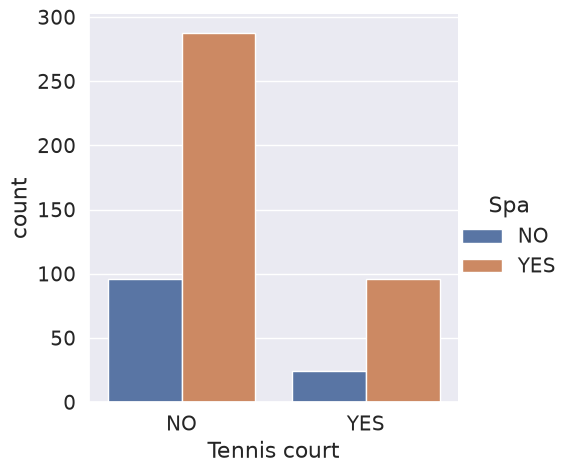

In [47]:
sns.catplot(x='Tennis court', data=reviews, kind='count', hue='Spa')

## Difficulties with categorical plots

/tmp/ipykernel_6780/613107894.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(x='Traveler type', kind='count', col='User continent',
/tmp/ipykernel_6780/613107894.py:1: UserWarning: The palette list has more values (9) than needed (5), which may not be intended.
  sns.catplot(x='Traveler type', kind='count', col='User continent',


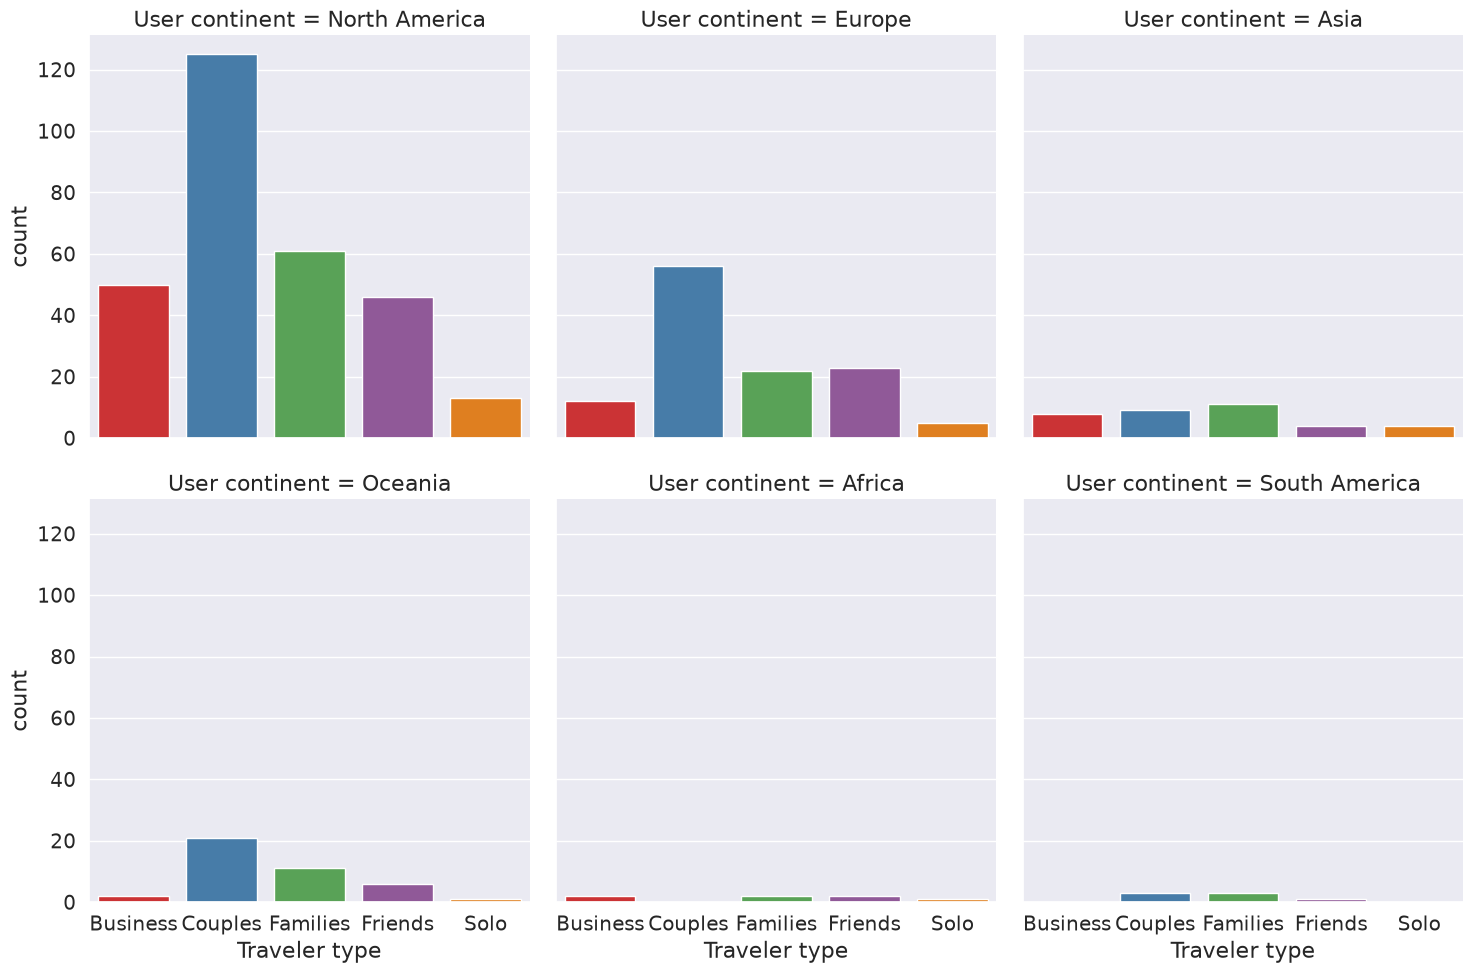

In [48]:
sns.catplot(x='Traveler type', kind='count', col='User continent',
            col_wrap=3,
            palette=sns.color_palette('Set1'), data=reviews)

The emphasis is on the counts within each category of user continent, and we have 6 clean graphics, all in one plot

## Updating plots

setup: save you graphic as an object: ax

/tmp/ipykernel_6780/1210069938.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.catplot(x='Traveler type', kind='count', col='User continent',
/tmp/ipykernel_6780/1210069938.py:1: UserWarning: The palette list has more values (9) than needed (5), which may not be intended.
  ax = sns.catplot(x='Traveler type', kind='count', col='User continent',


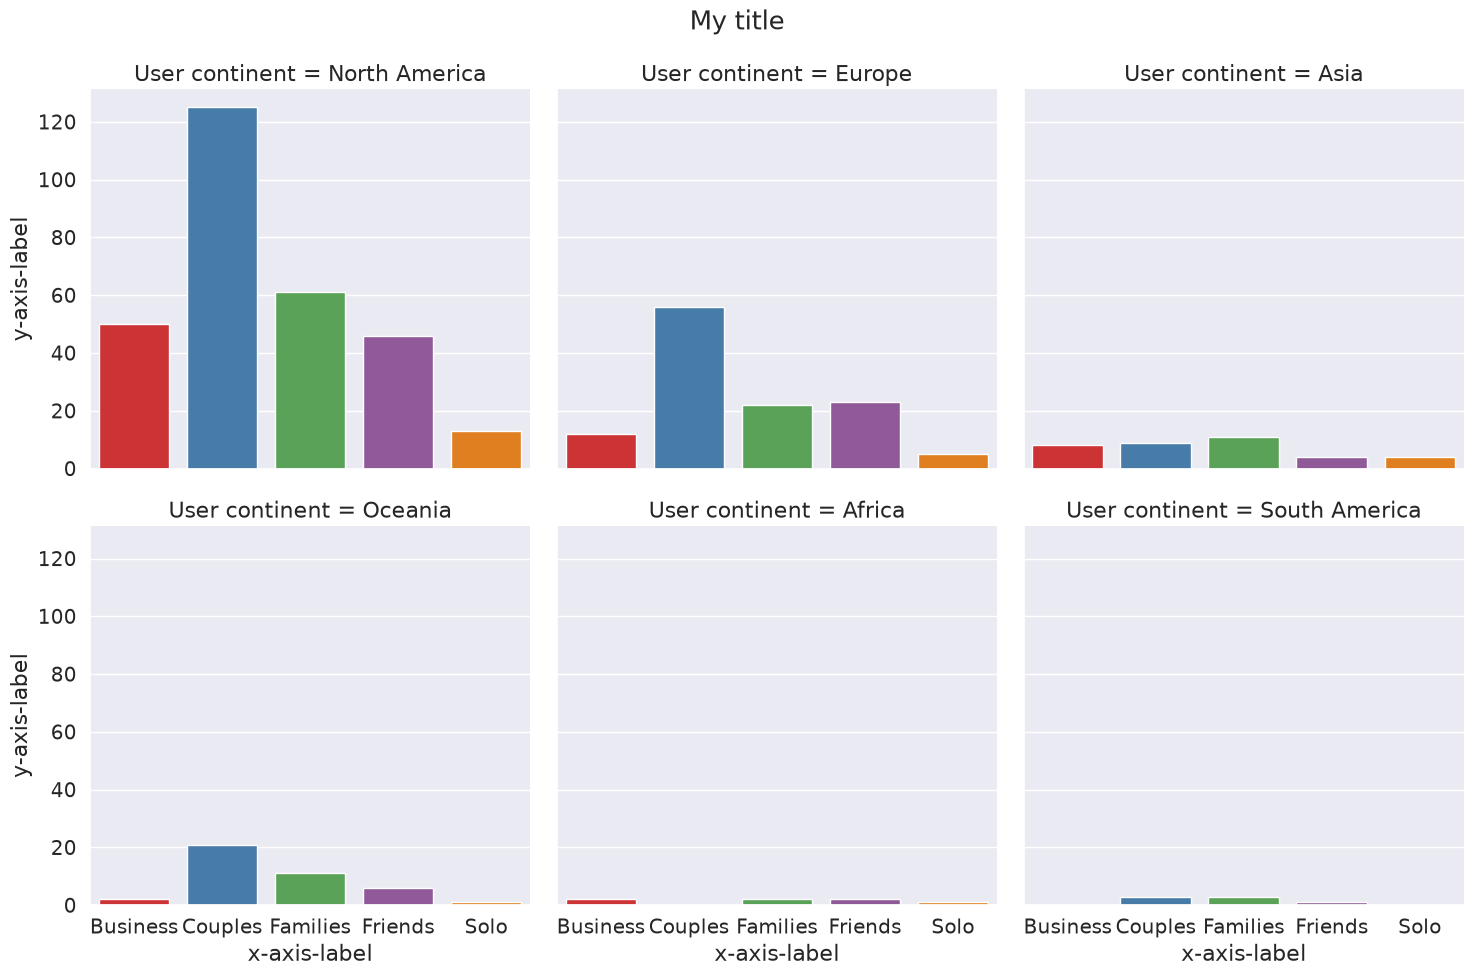

In [49]:
ax = sns.catplot(x='Traveler type', kind='count', col='User continent',
            col_wrap=3,
            palette=sns.color_palette('Set1'), data=reviews)

ax.fig.suptitle('My title') #plot title
ax.set_axis_labels('x-axis-label', 'y-axis-label') #axis labels
plt.subplots_adjust(top=.9) #title height


## Categorical pitfalls



In [50]:

# Download latest version
path = kagglehub.dataset_download("shivanink8/used-cars-dataset")

print("Path to dataset files:", path)

csv_path = os.path.join(path, 'used_cars.csv')

used_cars = pd.read_csv(csv_path)

Path to dataset files: /home/jubel/.cache/kagglehub/datasets/shivanink8/used-cars-dataset/versions/1


## Huge memory savings

In [51]:
used_cars.isna().sum()

id                        0
brand                     0
model                     0
year                      0
miles                     0
city_mileage              0
highway_mileage           0
horsepower                0
torque                    0
engine_capacity_litre     0
fuel_capacity             0
num_cylinder              0
num_seat                  0
num_owners                0
price                     0
link                      0
condition                51
type                      0
doors                     0
wheel_drive               0
engine_type               0
speed_levels              1
front_headroom            0
front_legroom             0
rear_headroom             0
rear_legroom              0
service_records           0
dtype: int64

In [52]:
used_cars['brand'].describe()

count        52
unique        6
top       Honda
freq         23
Name: brand, dtype: object

In [53]:
used_cars['brand'].nbytes

416

In [54]:
used_cars['brand'].astype('category').nbytes

100

We save lots of memory if we store the column as category instead of object!

However, if we convert a numerical column, or even an object column with lots of different unique values, we will see less memoy savings.

## Using categories can be frustrating

- .str accessor object to manipulate data converts the Series to an object

- The .apply() method outputs a new Series as an object

- the common methods of adding, removing , replaceing or setting categories do not all handle missing categories do not all handle missing categories the same way.

- NumPy functions generally do not work with categorical Series

## Check and convert

Any time you are updating categories, wether that is setting, adding or removing, use value-counts to make sure the changes you made worked as intended. With dropna=False

## Using NumPy arrays

we can quickly convert the series to an integer and use the sum method. This is common when using a categorical column that is an integer, such as the number of star for a hotel

In [55]:
used_cars['num_cylinder'].astype(int).sum()

np.int64(210)

In [56]:
used_cars['condition'].value_counts(dropna=False)

condition
NaN    51
4.0     1
Name: count, dtype: int64

## Label encoding

A technique that codes categorical values as integers.

Codse each category as an integer from 0 to n-1, where n is the number of categories. A -1 code is reserved for any missing values. 

Label encoding is used to save memory and to simplify responses when using survey data.

This is NOT the best encoding method for ML. 

Usually best when the categories are ordinal

In [57]:
used_cars.head()

,id,brand,model,year,miles,city_mileage,highway_mileage,horsepower,torque,engine_capacity_litre,...,type,doors,wheel_drive,engine_type,speed_levels,front_headroom,front_legroom,rear_headroom,rear_legroom,service_records
0,3,Chevrolet,Volt LT,2019,27173,43,42,149,294,1.5,...,sedan,4,2,hybrid_gas_electric,6.0,37.8,42.1,35.8,34.7,4
1,6,Hyundai,Elantra SE,2017,76941,29,38,146,132,2.0,...,sedan,4,2,gas,6.0,39.0,42.2,37.0,35.7,16
2,7,Ford,Focus,2014,97027,27,37,159,146,2.0,...,sedan,4,2,gas,6.0,38.3,43.7,38.0,33.2,13
3,8,Honda,Civic,2016,95396,31,42,158,138,1.5,...,sedan,4,2,gas,6.0,37.5,42.3,36.8,37.4,26
4,9,Hyundai,Elantra SE,2019,28405,29,38,147,132,2.0,...,sedan,4,2,gas,6.0,39.0,42.2,37.0,35.7,5


In [58]:
used_cars['brand'] = used_cars['brand'].astype('category')

used_cars['brand_code'] = used_cars['brand'].cat.codes

used_cars[['brand', 'brand_code']].value_counts()

brand       brand_code
Honda       2             23
Volkswagen  5             11
Hyundai     3              7
Ford        1              5
Chevrolet   0              3
Subaru      4              3
Hyundai     0              0
Ford        0              0
Honda       0              0
Subaru      0              0
Volkswagen  0              0
Chevrolet   3              0
Ford        3              0
Honda       3              0
Subaru      3              0
Volkswagen  3              0
Chevrolet   1              0
Hyundai     1              0
Honda       1              0
Subaru      1              0
Volkswagen  1              0
Chevrolet   2              0
Hyundai     2              0
Ford        2              0
Subaru      2              0
Volkswagen  2              0
Chevrolet   4              0
Hyundai     4              0
Ford        4              0
Honda       4              0
Volkswagen  4              0
Chevrolet   5              0
Hyundai     5              0
Ford        5       

.cat.codes converts the values to ints. If the column is not ordinal, the codes will be assignes in alphabetical order.  

## Creating a code book

If you do create a label encoding and save the daatset, you will want to create a map from the new codes to the old values.

This can be done by creating an object for the codes and an object for the categories.

We use zip, and by putting it in a dict the unique combinations of codes and categories will be added as key-value pairs.


In [59]:
codes = used_cars['brand'].cat.codes

categories = used_cars['brand']

name_map = dict(zip(codes, categories))

name_map

{0: 'Chevrolet',
 3: 'Hyundai',
 1: 'Ford',
 2: 'Honda',
 4: 'Subaru',
 5: 'Volkswagen'}

we can then use the name map we just created to convert the codes back to their original categorical values. 

This happens a lot when using surveys, as responses are often stored as numbers to save on memory. 

We can convert the column back to the original categories using the .map() method and specifying our name map

In [60]:
used_cars['brand_code'].map(name_map)

0      Chevrolet
1        Hyundai
2           Ford
3          Honda
4        Hyundai
5          Honda
6         Subaru
7          Honda
8     Volkswagen
9     Volkswagen
10         Honda
11         Honda
12         Honda
13         Honda
14         Honda
15        Subaru
16         Honda
17         Honda
18         Honda
19    Volkswagen
20          Ford
21          Ford
22     Chevrolet
23    Volkswagen
24    Volkswagen
25    Volkswagen
26         Honda
27         Honda
28       Hyundai
29         Honda
30       Hyundai
31         Honda
32        Subaru
33    Volkswagen
34    Volkswagen
35         Honda
36     Chevrolet
37    Volkswagen
38         Honda
39          Ford
40         Honda
41         Honda
42         Honda
43         Honda
44    Volkswagen
45    Volkswagen
46         Honda
47       Hyundai
48       Hyundai
49          Ford
50       Hyundai
51         Honda
Name: brand_code, dtype: str

.map() is similar to .replace(), and it will replace the Series values based on the keys of the name_map and their corresponing values.

## Boolean coding

When creating a label encoding for a categorical column, it is common to create a Boolean code that represents a group of categories. 

In [61]:
# Create a boolean column based on if the engine name that contain hybrid
import numpy as np

used_cars['is_volkswagen'] = np.where(
        used_cars['brand'].str.contains('Volkswagen', regex=False),
        True, False
)

In [62]:
used_cars.head()

# check out the new column

,id,brand,model,year,miles,city_mileage,highway_mileage,horsepower,torque,engine_capacity_litre,...,wheel_drive,engine_type,speed_levels,front_headroom,front_legroom,rear_headroom,rear_legroom,service_records,brand_code,is_volkswagen
0,3,Chevrolet,Volt LT,2019,27173,43,42,149,294,1.5,...,2,hybrid_gas_electric,6.0,37.8,42.1,35.8,34.7,4,0,False
1,6,Hyundai,Elantra SE,2017,76941,29,38,146,132,2.0,...,2,gas,6.0,39.0,42.2,37.0,35.7,16,3,False
2,7,Ford,Focus,2014,97027,27,37,159,146,2.0,...,2,gas,6.0,38.3,43.7,38.0,33.2,13,1,False
3,8,Honda,Civic,2016,95396,31,42,158,138,1.5,...,2,gas,6.0,37.5,42.3,36.8,37.4,26,2,False
4,9,Hyundai,Elantra SE,2019,28405,29,38,147,132,2.0,...,2,gas,6.0,39.0,42.2,37.0,35.7,5,3,False


## One-hot encoding

short intro.

Why not just use label encoding?

Better with nominal categories without order. So that the model in ML doesnt give meaning to the numbers.

pd.get_dummies()

One-hot encoding is the process of creating dummy variables, hence the name get-dummies.

data=

columns=

prefix=



In [64]:
used_cars['brand'].value_counts()

brand
Honda         23
Volkswagen    11
Hyundai        7
Ford           5
Chevrolet      3
Subaru         3
Name: count, dtype: int64

In [66]:
used_cars[['brand' , 'engine_type']].head()

,brand,engine_type
0,Chevrolet,hybrid_gas_electric
1,Hyundai,gas
2,Ford,gas
3,Honda,gas
4,Hyundai,gas


In [68]:
used_cars_onehot = pd.get_dummies(used_cars[['brand', 'engine_type']])
used_cars_onehot.head()

,brand_Chevrolet,brand_Ford,brand_Honda,brand_Hyundai,brand_Subaru,brand_Volkswagen,engine_type_gas,engine_type_hybrid_gas_electric
0,True,False,False,False,False,False,False,True
1,False,False,False,True,False,False,True,False
2,False,True,False,False,False,False,True,False
3,False,False,True,False,False,False,True,False
4,False,False,False,True,False,False,True,False


New columns with Tru/False - the orginial columns are dropped-




### Specifying columns to use

It may be important to use get-dummies on only a subset of columns, as you may not want to encode all object or categorical variables.

In [69]:
used_cars_onehot = pd.get_dummies(used_cars, columns=['engine_type'], prefix="")
used_cars_onehot.head()

,id,brand,model,year,miles,city_mileage,highway_mileage,horsepower,torque,engine_capacity_litre,...,speed_levels,front_headroom,front_legroom,rear_headroom,rear_legroom,service_records,brand_code,is_volkswagen,_gas,_hybrid_gas_electric
0,3,Chevrolet,Volt LT,2019,27173,43,42,149,294,1.5,...,6.0,37.8,42.1,35.8,34.7,4,0,False,False,True
1,6,Hyundai,Elantra SE,2017,76941,29,38,146,132,2.0,...,6.0,39.0,42.2,37.0,35.7,16,3,False,True,False
2,7,Ford,Focus,2014,97027,27,37,159,146,2.0,...,6.0,38.3,43.7,38.0,33.2,13,1,False,True,False
3,8,Honda,Civic,2016,95396,31,42,158,138,1.5,...,6.0,37.5,42.3,36.8,37.4,26,2,False,True,False
4,9,Hyundai,Elantra SE,2019,28405,29,38,147,132,2.0,...,6.0,39.0,42.2,37.0,35.7,5,3,False,True,False


specifying columns to onehot encode with columns=[] leaves all the other columns as they were.

## A few quick notes

First, if your columns have a lot of unique values, an equal amount of new columns will be created. Training machine larning models on a lot of columns may lead to overfitting. 

Secondly, NaN values do not get their own column. This is ok though. If all created columns for a variable are 0/False, this indicated that the original column was blank. 

